<b>DV Experiment 7: Heatmaps and Tree Maps</b><br><br><b>Aim:</b> Visualize numerical store correlations via a heatmap and hierarchical Category > Sub-Category sales via static and interactive treemaps.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
import plotly.express as px

In [2]:
data_dir = "datasets" if os.path.exists("datasets") else os.path.join("DV_Lab", "datasets")
out_dir = "outputs" if os.path.exists("outputs") else (os.path.join("DV_Lab", "outputs") if os.path.exists("DV_Lab") else "outputs")
os.makedirs(out_dir, exist_ok=True)

orders_df = pd.read_csv(os.path.join(data_dir, "superstore_sample.csv"))
cust_df = pd.read_csv(os.path.join(data_dir, "Dim_Customer.csv"))
df = orders_df.merge(cust_df, on="Customer_ID", how="left")

In [3]:
num_cols = ["Quantity", "Unit_Price", "Discount", "Sales", "Cost", "Profit"]
corr_matrix = df[num_cols].corr().round(3)
print("Correlation Matrix:")
print(corr_matrix)

cat_sub = (
    df.groupby(["Category", "Sub_Category"], as_index=False)[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)
print("\nMultilevel Category -> Sub-Category Sales:")
print(cat_sub.round(2).to_string(index=False))

Correlation Matrix:
            Quantity  Unit_Price  Discount  Sales   Cost  Profit
Quantity       1.000      -0.044     0.044  0.495  0.483   0.486
Unit_Price    -0.044       1.000     0.068  0.750  0.757   0.575
Discount       0.044       0.068     1.000  0.022  0.057  -0.205
Sales          0.495       0.750     0.022  1.000  0.997   0.848
Cost           0.483       0.757     0.057  0.997  1.000   0.801
Profit         0.486       0.575    -0.205  0.848  0.801   1.000

Multilevel Category -> Sub-Category Sales:
       Category Sub_Category     Sales   Profit
     Technology      Laptops 192874.78 23399.97
     Technology       Phones  95686.18 16721.48
      Furniture       Tables  69239.37  5608.77
      Furniture    Bookcases  60615.71  5204.76
      Furniture       Chairs  55962.19  7789.48
Office Supplies      Storage  37790.67  6213.44
     Technology  Accessories  20430.30  5572.24
Office Supplies      Binders  11498.00  2879.86
Office Supplies        Paper   9806.00  3106.65


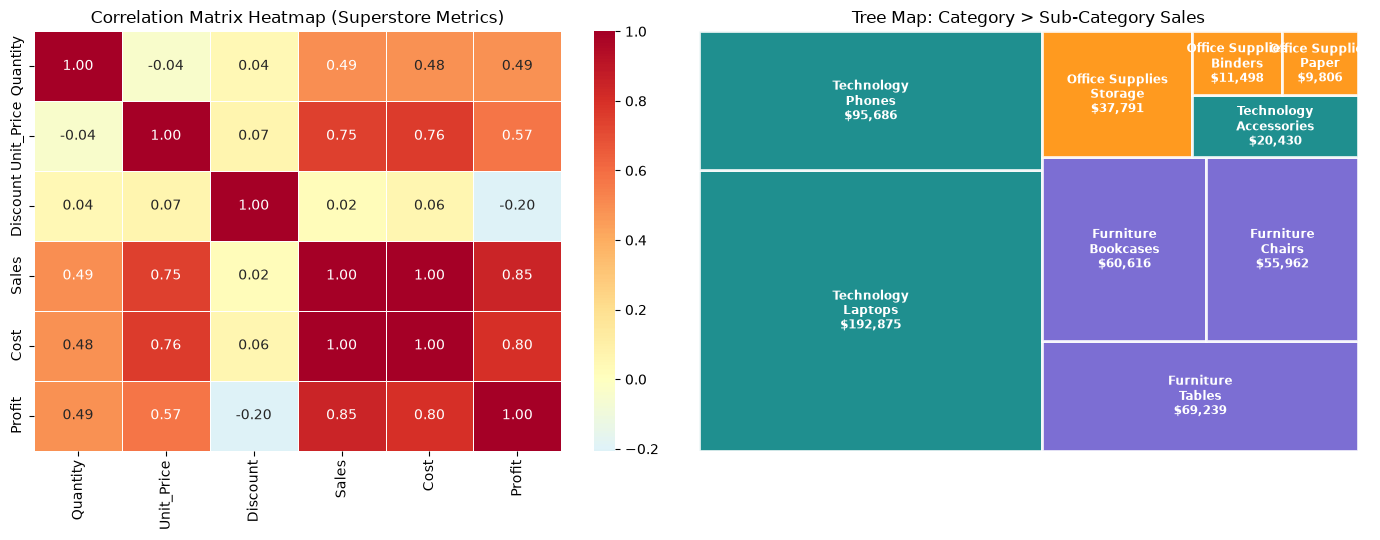

Interactive Treemap saved to: outputs\DV_Exp7_Interactive_Treemap.html


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0.0,
    linewidths=0.6,
    ax=ax[0],
)
ax[0].set_title("Correlation Matrix Heatmap (Superstore Metrics)")

treemap_labels = [
    f"{row['Category']}\n{row['Sub_Category']}\n${row['Sales']:,.0f}"
    for _, row in cat_sub.iterrows()
]
cat_palette = {
    "Technology": "teal",
    "Furniture": "slateblue",
    "Office Supplies": "darkorange",
}
treemap_colors = [cat_palette[c] for c in cat_sub["Category"]]

squarify.plot(
    sizes=cat_sub["Sales"],
    label=treemap_labels,
    color=treemap_colors,
    alpha=0.88,
    edgecolor="white",
    linewidth=2,
    text_kwargs={"fontsize": 8.5, "color": "white", "fontweight": "bold"},
    ax=ax[1],
)
ax[1].set_title("Tree Map: Category > Sub-Category Sales")
ax[1].axis("off")

plt.tight_layout()
plt.show()

tree_fig = px.treemap(
    df,
    path=[px.Constant("All Categories"), "Category", "Sub_Category", "Loyalty_Tier"],
    values="Sales",
    color="Profit",
    color_continuous_scale="Tealrose",
    title="Interactive Multilevel Tree Map (Category > Sub-Category > Loyalty Tier)",
)
html_path = os.path.join(out_dir, "DV_Exp7_Interactive_Treemap.html")
tree_fig.write_html(html_path, include_plotlyjs="cdn")
print("Interactive Treemap saved to:", html_path)

<b>Observation:</b> Sales correlates positively with Cost and Profit while Discount correlates negatively with Profit; treemaps show Laptops and Tables dominating volume.